# Trabalho 1 — Estudo Comparativo de Modelos e Prompts

**Disciplina:** Geração de Linguagem Natural e Engenharia de Prompt  
**Curso:** Pós-Graduação em IA Generativa e Aplicações com LLMs — PUC Minas

Neste notebook eu organizei o experimento do Trabalho 1. A ideia foi comparar três modelos de linguagem usando os mesmos prompts e o mesmo texto-base.

Os modelos utilizados foram:

- Gemini
- Grok
- Claude

Eu mantive as respostas originais para fazer a avaliação sem alterar o que os modelos responderam.

> **Observação:** quando uma informação não estava disponível na interface, deixei isso indicado em vez de criar um valor fictício.

## 1. Objetivo

O objetivo deste trabalho é comparar três modelos de linguagem em condições controladas, utilizando os mesmos prompts, texto-base e critérios de avaliação.

A pergunta que estou tentando responder com o experimento é:

> **Qual modelo e configuração atendem melhor ao projeto pretendido?**

A análise considera qualidade, consistência, aderência aos formatos, segurança, custo, latência, falhas e adequação ao projeto.


In [1]:
# Instalação opcional de dependências
# Execute esta célula caso o ambiente ainda não possua as bibliotecas utilizadas.

%pip install pandas numpy matplotlib seaborn openpyxl -q


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
import re
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_columns", 50)

print("Ambiente carregado com sucesso.")


Ambiente carregado com sucesso.


## 2. Texto-base utilizado em todas as execuções

O texto-base permanece idêntico entre os modelos, conforme especificado no trabalho.


In [3]:
texto_base = """A empresa fictícia Aurora Tech adotará uma política-piloto de trabalho híbrido entre 1º de setembro e 30 de novembro. Colaboradores elegíveis poderão trabalhar remotamente até dois dias por semana, definidos com o gestor. As equipes deverão manter presença comum às terças-feiras para reuniões e atividades colaborativas. O benefício não se aplica a funções que dependam de atendimento presencial, operação de laboratório ou manutenção física. Exceções deverão ser aprovadas pela diretoria da área e registradas pelo RH. O colaborador deverá manter disponibilidade entre 9h e 17h, utilizar autenticação multifator e acessar documentos corporativos somente por dispositivos gerenciados. Despesas de internet e energia não serão reembolsadas durante o piloto. Os gestores acompanharão prazo das entregas, qualidade, colaboração e satisfação da equipe. O RH aplicará uma pesquisa no início e no final do período. Incidentes de segurança deverão ser informados imediatamente ao Service Desk. Ao término do piloto, a diretoria decidirá se a política será mantida, alterada ou encerrada. Dúvidas devem ser encaminhadas ao canal interno RH Responde."""

print(texto_base)


A empresa fictícia Aurora Tech adotará uma política-piloto de trabalho híbrido entre 1º de setembro e 30 de novembro. Colaboradores elegíveis poderão trabalhar remotamente até dois dias por semana, definidos com o gestor. As equipes deverão manter presença comum às terças-feiras para reuniões e atividades colaborativas. O benefício não se aplica a funções que dependam de atendimento presencial, operação de laboratório ou manutenção física. Exceções deverão ser aprovadas pela diretoria da área e registradas pelo RH. O colaborador deverá manter disponibilidade entre 9h e 17h, utilizar autenticação multifator e acessar documentos corporativos somente por dispositivos gerenciados. Despesas de internet e energia não serão reembolsadas durante o piloto. Os gestores acompanharão prazo das entregas, qualidade, colaboração e satisfação da equipe. O RH aplicará uma pesquisa no início e no final do período. Incidentes de segurança deverão ser informados imediatamente ao Service Desk. Ao término d

## 3. Prompts

Aqui eu deixei os quatro prompts em variáveis para conseguir repetir o experimento sem precisar copiar e colar tudo novamente.


In [4]:
prompts = {
    "P1": """TAREFA: produzir um resumo executivo.

CONTEXTO: você apoia uma diretoria que precisa compreender rapidamente uma política interna.

INSTRUÇÕES:
1. Use somente informações do texto fornecido.
2. Produza de 100 a 130 palavras.
3. Destaque objetivo, período, elegibilidade, regras, controles e forma de avaliação.
4. Não invente justificativas, benefícios ou exceções.

FORMATO:
Um título e um único parágrafo.

TEXTO:
[TEXTO-BASE]""".replace("[TEXTO-BASE]", texto_base),

    "P2": """TAREFA: reescrever a política como comunicado aos colaboradores.

PÚBLICO:
Profissionais da empresa com diferentes níveis de conhecimento técnico.

INSTRUÇÕES:
1. Use linguagem clara, cordial e objetiva.
2. Preserve datas, condições, exceções e responsabilidades.
3. Organize em:
   - assunto;
   - abertura;
   - regras principais em tópicos;
   - canal para dúvidas.
4. Não inclua promessas ou regras ausentes no texto.

TEXTO:
[TEXTO-BASE]""".replace("[TEXTO-BASE]", texto_base),

    "P3": """TAREFA:
Extrair informações estruturadas da política.

INSTRUÇÕES:
1. Use somente o texto fornecido.
2. Se uma informação não existir, use null.
3. Retorne JSON válido, sem comentários antes ou depois.
4. Use exatamente as chaves abaixo.

FORMATO:
{
  "periodo_inicio": "AAAA-MM-DD ou null",
  "periodo_fim": "AAAA-MM-DD ou null",
  "dias_remotos_maximo": 0,
  "dia_presencial_comum": "",
  "horario_disponibilidade": "",
  "funcoes_nao_elegiveis": [],
  "controles_seguranca": [],
  "canal_duvidas": ""
}

TEXTO:
[TEXTO-BASE]""".replace("[TEXTO-BASE]", texto_base),

    "P4": """TAREFA:
Criar uma FAQ para gestores sobre a política-piloto.

INSTRUÇÕES:
1. Crie exatamente 6 perguntas e respostas.
2. Cubra:
   - elegibilidade;
   - definição dos dias;
   - presença comum;
   - exceções;
   - acompanhamento;
   - segurança.
3. Cada resposta deve ter no máximo 45 palavras.
4. Use somente o texto fornecido.
5. Quando a política não trouxer detalhe suficiente, declare que o gestor deve consultar o RH Responde.

FORMATO:
Numere de 1 a 6 e use:

Pergunta:
Resposta:

TEXTO:
[TEXTO-BASE]""".replace("[TEXTO-BASE]", texto_base)
}

for codigo, prompt in prompts.items():
    print(f"{codigo}: {len(prompt.split())} palavras no prompt")


P1: 223 palavras no prompt
P2: 224 palavras no prompt
P3: 225 palavras no prompt
P4: 242 palavras no prompt


## 4. Respostas dos modelos

As respostas abaixo são as respostas que eu obtive e coloquei no experimento. Eu mantive o conteúdo bruto para não alterar o resultado antes da avaliação. para Gemini, Grok e Claude. Eles são tratados como **dados brutos** e não são corrigidos antes da avaliação.


In [5]:
resultados = {
    "Gemini": {
        "P1": """Título:
Política-Piloto de Trabalho Híbrido da Aurora Tech

Resumo:
A Aurora Tech implementará uma política-piloto de trabalho híbrido entre 1º de setembro e 30 de novembro com o objetivo de testar o modelo flexível. O benefício contempla colaboradores elegíveis, excluindo funções de atendimento presencial, operação de laboratório ou manutenção física. Participantes poderão cumprir até dois dias remotos por semana, devendo manter presença presencial comum às terças-feiras e disponibilidade das 9h às 17h, sem reembolso de despesas operacionais. Como controles de segurança, exige-se autenticação multifator, uso exclusivo de dispositivos gerenciados e reporte imediato de incidentes ao Service Desk. O acompanhamento considerará entregas, qualidade, colaboração, satisfação e pesquisas do RH, fundamentando a decisão final da diretoria sobre a continuidade, alteração ou encerramento da política.""",

        "P2": """Assunto:
Lançamento da Política-Piloto de Trabalho Híbrido Aurora Tech

Abertura:
Prezados colaboradores, comunicamos que a Aurora Tech adotará uma política-piloto de trabalho híbrido no período de 1º de setembro a 30 de novembro.

Regras principais:
Colaboradores elegíveis poderão trabalhar remotamente até dois dias por semana, definidos em alinhamento com o gestor, mantendo presença presencial obrigatória de toda a equipe às terças-feiras.

O benefício não se aplica a funções de atendimento presencial, operação de laboratório ou manutenção física, sendo que eventuais exceções exigem aprovação da diretoria e registro no RH.

O colaborador deve manter disponibilidade das 9h às 17h, utilizar autenticação multifator e acessar documentos corporativos exclusivamente por dispositivos gerenciados.

Despesas com internet e energia não serão reembolsadas durante o piloto, e qualquer incidente de segurança deve ser comunicado imediatamente ao Service Desk.

Os gestores e o RH acompanharão o desempenho, entregas e satisfação da equipe para que a diretoria decida sobre a manutenção, alteração ou encerramento da política ao final do período.

Canal para dúvidas:
Dúvidas devem ser encaminhadas ao canal interno RH Responde.""",

        "P3": '''{"periodo_inicio": "1º de setembro","periodo_fim": "30 de novembro","dias_remotos_maximo": 2,"dia_presencial_comum": "terças-feiras","horario_disponibilidade": "9h e 17h","funcoes_nao_elegiveis": ["atendimento presencial","operação de laboratório","manutenção física"],"controles_seguranca": ["autenticação multifator","acesso a documentos corporativos somente por dispositivos gerenciados","comunicação imediata de incidentes de segurança ao Service Desk"],"canal_duvidas": "RH Responde"}''',

        "P4": """1. Pergunta: Quais colaboradores são elegíveis para participar da política-piloto de trabalho híbrido?
Resposta: O benefício aplica-se aos colaboradores elegíveis. Não são elegíveis as funções que dependam de atendimento presencial, operação de laboratório ou manutenção física. Para dúvidas específicas sobre funções, o gestor deve consultar o canal RH Responde.

2. Pergunta: Como devem ser definidos os dias de trabalho remoto dos colaboradores?
Resposta: Os colaboradores elegíveis podem trabalhar remotamente até dois dias por semana. Os dias específicos de trabalho remoto devem ser definidos diretamente entre o colaborador e o seu gestor.

3. Pergunta: Existe algum dia fixo em que toda a equipe deve estar presencialmente na empresa?
Resposta: Sim. As equipes devem manter obrigatoriamente a presença comum presencial às terças-feiras para a realização de reuniões e atividades colaborativas.

4. Pergunta: É possível abrir exceções às regras da política de trabalho híbrido?
Resposta: Sim. Caso ocorram exceções à política, elas deverão ser aprovadas pela diretoria da respectiva área e devidamente registradas pelo setor de RH.

5. Pergunta: Como os gestores devem realizar o acompanhamento dos resultados das equipes?
Resposta: Os gestores acompanharão o prazo das entregas, a qualidade do trabalho, a colaboração e a satisfação da equipe. Além disso, o RH aplicará uma pesquisa no início e no final do período.

6. Pergunta: Quais são as diretrizes de segurança da informação aplicáveis ao modelo híbrido?
Resposta: O colaborador deve manter disponibilidade entre 9h e 17h, utilizar autenticação multifator e acessar documentos corporativos apenas por dispositivos gerenciados. Incidentes devem ser informados ao Service Desk."""
    },

    "Grok": {
        "P1": """Título:
Política-piloto de Trabalho Híbrido da Aurora Tech

Resumo:
A Aurora Tech implementará política-piloto de trabalho híbrido de 1º de setembro a 30 de novembro. Colaboradores elegíveis poderão atuar remotamente até dois dias por semana, definidos com o gestor, mantendo presença comum às terças-feiras. Funções de atendimento presencial, laboratório ou manutenção física não são elegíveis; exceções exigem aprovação da diretoria e registro no RH. É obrigatória disponibilidade das 9h às 17h, autenticação multifator e uso exclusivo de dispositivos gerenciados. Despesas de internet e energia não serão reembolsadas. Gestores acompanharão prazos, qualidade, colaboração e satisfação; o RH aplicará pesquisas no início e no fim. Incidentes de segurança devem ser reportados imediatamente ao Service Desk. Ao término, a diretoria decidirá sobre manutenção, alteração ou encerramento.""",

        "P2": """Assunto:
Política-piloto de Trabalho Híbrido – Aurora Tech (1º de setembro a 30 de novembro)

Abertura:
Comunicamos a adoção de uma política-piloto de trabalho híbrido, válida de 1º de setembro a 30 de novembro. O objetivo é testar o modelo de forma controlada, com regras claras de elegibilidade, presença e segurança.

Regras principais:
- Colaboradores elegíveis poderão trabalhar remotamente até dois dias por semana, definidos em conjunto com o gestor.
- As equipes devem manter presença comum às terças-feiras para reuniões e atividades colaborativas.
- O benefício não se aplica a funções que dependam de atendimento presencial, operação de laboratório ou manutenção física. Exceções devem ser aprovadas pela diretoria da área e registradas pelo RH.
- É obrigatório manter disponibilidade entre 9h e 17h, utilizar autenticação multifator e acessar documentos corporativos somente por dispositivos gerenciados.
- Despesas de internet e energia não serão reembolsadas durante o piloto.
- Gestores acompanharão prazos das entregas, qualidade, colaboração e satisfação da equipe. O RH aplicará pesquisa no início e no final do período.
- Incidentes de segurança devem ser informados imediatamente ao Service Desk.
- Ao término do piloto, a diretoria decidirá se a política será mantida, alterada ou encerrada.

Canal para dúvidas:
Encaminhe suas dúvidas ao canal interno RH Responde.""",

        "P3": '''{
  "periodo_inicio": "1º de setembro",
  "periodo_fim": "30 de novembro",
  "dias_remotos_maximo": 2,
  "dia_presencial_comum": "terças-feiras",
  "horario_disponibilidade": "9h e 17h",
  "funcoes_nao_elegiveis": [
    "atendimento presencial",
    "operação de laboratório",
    "manutenção física"
  ],
  "controles_seguranca": [
    "autenticação multifator",
    "acesso a documentos corporativos somente por dispositivos gerenciados",
    "comunicação imediata de incidentes de segurança ao Service Desk"
  ],
  "canal_duvidas": "RH Responde"
}''',

        "P4": """1. Pergunta: Quais funções são elegíveis para o trabalho remoto no piloto?
Resposta: São elegíveis os colaboradores cujas funções não dependam de atendimento presencial, operação de laboratório ou manutenção física. Em caso de dúvida sobre elegibilidade específica, consulte o canal RH Responde.

2. Pergunta: Como são definidos os dias remotos de cada colaborador?
Resposta: Os dias remotos (até dois por semana) são definidos em acordo entre o colaborador e o gestor. Não há indicação de critérios adicionais no texto da política.

3. Pergunta: Qual é a regra de presença presencial comum das equipes?
Resposta: As equipes deverão manter presença comum às terças-feiras para reuniões e atividades colaborativas.

4. Pergunta: Como funcionam as exceções à política?
Resposta: Exceções devem ser aprovadas pela diretoria da área e registradas pelo RH.

5. Pergunta: Como os gestores devem acompanhar os resultados do piloto?
Resposta: Os gestores acompanharão prazo das entregas, qualidade, colaboração e satisfação da equipe. O RH aplicará pesquisas no início e no final do período.

6. Pergunta: Quais são as obrigações de segurança da informação no trabalho remoto?
Resposta: O colaborador deve utilizar autenticação multifator, acessar documentos apenas por dispositivos gerenciados e informar imediatamente qualquer incidente de segurança ao Service Desk."""
    },

    "Claude": {
        "P1": """Título:
Resumo Executivo – Política-Piloto de Trabalho Híbrido (Aurora Tech)

Resumo:
Entre 1º de setembro e 30 de novembro, a Aurora Tech testará uma política-piloto de trabalho híbrido, com decisão futura da diretoria sobre sua manutenção, alteração ou encerramento. Colaboradores elegíveis poderão trabalhar remotamente até dois dias por semana, definidos com o gestor, mantendo presença comum às terças-feiras. Ficam fora funções que dependem de atendimento presencial, operação de laboratório ou manutenção física, e exceções exigem aprovação da diretoria da área e registro do RH. As regras de segurança incluem disponibilidade das 9h às 17h, autenticação multifator, acesso a documentos corporativos apenas por dispositivos gerenciados e comunicação imediata de incidentes ao Service Desk. Despesas de internet e energia não são reembolsadas. O acompanhamento cabe aos gestores (prazos, qualidade, colaboração, satisfação) e ao RH, via pesquisas no início e no fim do piloto.""",

        "P2": """Assunto:
Início da Política-Piloto de Trabalho Híbrido

Abertura:
Prezados colaboradores,

Informamos que a Aurora Tech implementará, entre 1º de setembro e 30 de novembro, uma política-piloto de trabalho híbrido. Este comunicado apresenta as principais regras que estarão em vigor durante o período de teste.

Regras principais:

Vigência: de 1º de setembro a 30 de novembro (período-piloto).
Dias remotos: colaboradores elegíveis podem trabalhar remotamente até 2 dias por semana, definidos junto ao gestor.
Presença em equipe: comparecimento obrigatório às terças-feiras para reuniões e atividades colaborativas.
Elegibilidade: a política não se aplica a funções que dependam de atendimento presencial, operação de laboratório ou manutenção física.
Exceções: devem ser aprovadas pela diretoria da área e registradas pelo RH.
Disponibilidade e acesso: é necessário manter disponibilidade das 9h às 17h, usar autenticação multifator e acessar documentos corporativos somente por dispositivos gerenciados pela empresa.
Despesas: custos de internet e energia não serão reembolsados durante o piloto.
Acompanhamento: os gestores avaliarão prazos, qualidade, colaboração e satisfação da equipe; o RH aplicará pesquisas no início e no fim do piloto.
Segurança da informação: qualquer incidente de segurança deve ser reportado imediatamente ao Service Desk.
Encerramento: ao final do piloto, a diretoria decidirá se a política será mantida, alterada ou encerrada.

Canal para dúvidas:
Em caso de dúvidas sobre a política, entre em contato pelo canal interno RH Responde.""",

        "P3": '''{
  "periodo_inicio": "1º de setembro",
  "periodo_fim": "30 de novembro",
  "dias_remotos_maximo": 2,
  "dia_presencial_comum": "terça-feira",
  "horario_disponibilidade": "9h às 17h",
  "funcoes_nao_elegiveis": [
    "atendimento presencial",
    "operação de laboratório",
    "manutenção física"
  ],
  "controles_seguranca": [
    "autenticação multifator",
    "acesso a documentos corporativos somente por dispositivos gerenciados",
    "comunicação imediata de incidentes de segurança ao Service Desk"
  ],
  "canal_duvidas": "RH Responde"
}''',

        "P4": """1. Pergunta: Quais colaboradores são elegíveis à política de trabalho híbrido?
Resposta: São elegíveis os colaboradores cujas funções não dependam de atendimento presencial, operação de laboratório ou manutenção física. Casos específicos de elegibilidade devem ser verificados com o RH pelo canal RH Responde.

2. Pergunta: Como são definidos os dias de trabalho remoto de cada colaborador?
Resposta: Colaboradores elegíveis podem trabalhar remotamente até dois dias por semana, definidos em conjunto com o gestor direto, respeitando a presença obrigatória em equipe às terças-feiras.

3. Pergunta: Existe um dia fixo de presença presencial para as equipes?
Resposta: Sim. As equipes devem manter presença comum às terças-feiras, destinadas a reuniões e atividades colaborativas presenciais, independentemente dos dias remotos escolhidos por cada colaborador.

4. Pergunta: Como um gestor pode solicitar uma exceção à política?
Resposta: Exceções devem ser aprovadas pela diretoria da área responsável e registradas formalmente pelo RH. O texto não detalha o processo de solicitação; consulte o canal RH Responde para orientações.

5. Pergunta: Como serão acompanhados os resultados do piloto?
Resposta: Os gestores acompanharão prazos de entrega, qualidade, colaboração e satisfação da equipe. O RH também aplicará uma pesquisa no início e no final do período do piloto.

6. Pergunta: Quais são as exigências de segurança da informação durante o trabalho remoto?
Resposta: É necessário manter disponibilidade das 9h às 17h, utilizar autenticação multifator e acessar documentos corporativos apenas por dispositivos gerenciados. Incidentes de segurança devem ser informados imediatamente ao Service Desk."""
    }
}

assert set(resultados.keys()) == {"Gemini", "Grok", "Claude"}
assert all(set(v.keys()) == {"P1", "P2", "P3", "P4"} for v in resultados.values())

print("12 resultados brutos carregados.")


12 resultados brutos carregados.


## 5. Como organizei os dados

Eu organizei as execuções em uma tabela para conseguir visualizar os 12 casos: três modelos × quatro prompts.

As respostas que já estavam disponíveis foram usadas como resultado bruto. Para os dados de API que não apareceram, mantive a indicação de indisponibilidade.

## 6. Metadados das execuções

As informações não presentes nos resultados fornecidos não são inferidas. Isso inclui versão, temperatura efetiva, top-p, limite de tokens, latência, quantidade de tokens e custo.


### Nota sobre os dados coletados

Os metadados abaixo foram obtidos das respostas fornecidas para o notebook. A coleta informou que as interfaces não disponibilizaram telemetria detalhada para tokens, latência, custos e parâmetros efetivos. Esses campos permanecem sem preenchimento artificial.

In [6]:
metadados_modelos = pd.DataFrame([
    ["Gemini 3.1 Pro Preview", "Google", "Gemini 3.1 Pro Preview",
     "11/08/2026 21:45", "Não informado", "Não informado",
     "Não informado", "US$ 2 / 1M tokens de entrada (≤200k); US$ 12 / 1M tokens de saída"],
    ["Grok 4.5", "xAI", "Grok 4.5",
     "10/08/2026 11:00", "Não informado", "Não informado",
     "Não informado", "US$ 2 / 1M tokens de entrada; US$ 6 / 1M tokens de saída"],
    ["Claude Sonnet 5", "Anthropic", "Claude Sonnet 5",
     "12/08/2026 14:03", "Não informado", "Não informado",
     "Não informado", "US$ 2 / 1M tokens de entrada; US$ 10 / 1M tokens de saída"],
], columns=[
    "Modelo", "Fornecedor", "Versão", "Data/hora do teste",
    "Temperatura", "Top-p", "Limite de tokens", "Preços informados"
])

metadados_modelos


,Modelo,Fornecedor,Versão,Data/hora do teste,Temperatura,Top-p,Limite de tokens,Preços informados
0,Gemini 3.1 Pro Preview,Google,Gemini 3.1 Pro Preview,11/08/2026 21:45,Não informado,Não informado,Não informado,US$ 2 / 1M tokens de entrada (≤200k); US$ 12 / 1M tokens de saída
1,Grok 4.5,xAI,Grok 4.5,10/08/2026 11:00,Não informado,Não informado,Não informado,US$ 2 / 1M tokens de entrada; US$ 6 / 1M tokens de saída
2,Claude Sonnet 5,Anthropic,Claude Sonnet 5,12/08/2026 14:03,Não informado,Não informado,Não informado,US$ 2 / 1M tokens de entrada; US$ 10 / 1M tokens de saída


In [7]:
dados_api = {
    "Gemini 3.1 Pro Preview": {
        "versao": "Gemini 3.1 Pro Preview",
        "data_hora": "11/08/2026 21:45",
        "temperatura": "Não informado",
        "top_p": "Não informado",
        "limite_tokens": "Não informado",
        "latencia": "≈ 27,16 s TTFT; ≈ 125,9 tokens/s",
        "tokens": "Não disponível na execução",
        "custo": "US$ 2 / 1M entrada (≤200k); US$ 12 / 1M saída",
        "erros": "Nenhum",
        "recusas": "Nenhuma",
        "truncamentos": "Não informado",
        "obs": "Preços fornecidos para o experimento. A latência e a quantidade efetiva de tokens ainda precisam ser medidas na execução."
    },
    "Grok 4.5": {
        "versao": "Grok 4.5",
        "data_hora": "10/08/2026 11:00",
        "temperatura": "Não informado",
        "top_p": "Não informado",
        "limite_tokens": "Não informado",
        "latencia": "≈ 9,76 s TTFT; ≈ 60,4 tokens/s",
        "tokens": "Não disponível na execução",
        "custo": "US$ 2 / 1M entrada; US$ 6 / 1M saída",
        "erros": "Nenhum",
        "recusas": "Nenhuma",
        "truncamentos": "Não informado",
        "obs": "Preços fornecidos para o experimento. A latência e a quantidade efetiva de tokens ainda precisam ser medidas na execução."
    },
    "Claude Sonnet 5": {
        "versao": "Claude Sonnet 5",
        "data_hora": "12/08/2026 14:03",
        "temperatura": "Não informado",
        "top_p": "Não informado",
        "limite_tokens": "Não informado",
        "latencia": "Não encontrado benchmark público confiável específico do Sonnet 5",
        "tokens": "Não disponível na execução",
        "custo": "US$ 2 / 1M entrada; US$ 10 / 1M saída",
        "erros": "Nenhum",
        "recusas": "Nenhuma",
        "truncamentos": "Não informado",
        "obs": "Preços fornecidos para o experimento. A latência e a quantidade efetiva de tokens ainda precisam ser medidas na execução."
    }
}

# Os resultados brutos já existentes no notebook estão associados aos nomes antigos.
# Aqui faço a correspondência para os novos nomes dos modelos.
mapa_modelos = {
    "Gemini": "Gemini 3.1 Pro Preview",
    "Grok": "Grok 4.5",
    "Claude": "Claude Sonnet 5"
}

resultados_atualizados = {
    mapa_modelos.get(modelo, modelo): prompts_resultados
    for modelo, prompts_resultados in resultados.items()
}

execucoes = []

for modelo in resultados_atualizados:
    meta = dados_api[modelo]
    for prompt in ["P1", "P2", "P3", "P4"]:
        execucoes.append({
            "Código": f"{modelo.split()[0][:1].upper()}-{prompt}",
            "Modelo": modelo,
            "Prompt": prompt,
            "Versão": meta["versao"],
            "Data/hora": meta["data_hora"],
            "Temperatura": meta["temperatura"],
            "Top-p": meta["top_p"],
            "Limite de tokens": meta["limite_tokens"],
            "Latência (s)": meta["latencia"],
            "Tokens": meta["tokens"],
            "Custo": meta["custo"],
            "Resultado bruto": resultados_atualizados[modelo][prompt],
            "Erros": meta["erros"],
            "Recusas": meta["recusas"],
            "Truncamentos": meta["truncamentos"],
            "Observações": meta["obs"]
        })

df_execucoes = pd.DataFrame(execucoes)

df_execucoes[[
    "Código", "Modelo", "Prompt", "Versão", "Data/hora",
    "Temperatura", "Top-p", "Limite de tokens",
    "Latência (s)", "Tokens", "Custo", "Erros",
    "Recusas", "Truncamentos"
]]


,Código,Modelo,Prompt,Versão,Data/hora,Temperatura,Top-p,Limite de tokens,Latência (s),Tokens,Custo,Erros,Recusas,Truncamentos
0,G-P1,Gemini 3.1 Pro Preview,P1,Gemini 3.1 Pro Preview,11/08/2026 21:45,Não informado,Não informado,Não informado,"≈ 27,16 s TTFT; ≈ 125,9 tokens/s",Não disponível na execução,US$ 2 / 1M entrada (≤200k); US$ 12 / 1M saída,Nenhum,Nenhuma,Não informado
1,G-P2,Gemini 3.1 Pro Preview,P2,Gemini 3.1 Pro Preview,11/08/2026 21:45,Não informado,Não informado,Não informado,"≈ 27,16 s TTFT; ≈ 125,9 tokens/s",Não disponível na execução,US$ 2 / 1M entrada (≤200k); US$ 12 / 1M saída,Nenhum,Nenhuma,Não informado
2,G-P3,Gemini 3.1 Pro Preview,P3,Gemini 3.1 Pro Preview,11/08/2026 21:45,Não informado,Não informado,Não informado,"≈ 27,16 s TTFT; ≈ 125,9 tokens/s",Não disponível na execução,US$ 2 / 1M entrada (≤200k); US$ 12 / 1M saída,Nenhum,Nenhuma,Não informado
3,G-P4,Gemini 3.1 Pro Preview,P4,Gemini 3.1 Pro Preview,11/08/2026 21:45,Não informado,Não informado,Não informado,"≈ 27,16 s TTFT; ≈ 125,9 tokens/s",Não disponível na execução,US$ 2 / 1M entrada (≤200k); US$ 12 / 1M saída,Nenhum,Nenhuma,Não informado
4,G-P1,Grok 4.5,P1,Grok 4.5,10/08/2026 11:00,Não informado,Não informado,Não informado,"≈ 9,76 s TTFT; ≈ 60,4 tokens/s",Não disponível na execução,US$ 2 / 1M entrada; US$ 6 / 1M saída,Nenhum,Nenhuma,Não informado
5,G-P2,Grok 4.5,P2,Grok 4.5,10/08/2026 11:00,Não informado,Não informado,Não informado,"≈ 9,76 s TTFT; ≈ 60,4 tokens/s",Não disponível na execução,US$ 2 / 1M entrada; US$ 6 / 1M saída,Nenhum,Nenhuma,Não informado
6,G-P3,Grok 4.5,P3,Grok 4.5,10/08/2026 11:00,Não informado,Não informado,Não informado,"≈ 9,76 s TTFT; ≈ 60,4 tokens/s",Não disponível na execução,US$ 2 / 1M entrada; US$ 6 / 1M saída,Nenhum,Nenhuma,Não informado
7,G-P4,Grok 4.5,P4,Grok 4.5,10/08/2026 11:00,Não informado,Não informado,Não informado,"≈ 9,76 s TTFT; ≈ 60,4 tokens/s",Não disponível na execução,US$ 2 / 1M entrada; US$ 6 / 1M saída,Nenhum,Nenhuma,Não informado
8,C-P1,Claude Sonnet 5,P1,Claude Sonnet 5,12/08/2026 14:03,Não informado,Não informado,Não informado,Não encontrado benchmark público confiável específico do Sonnet 5,Não disponível na execução,US$ 2 / 1M entrada; US$ 10 / 1M saída,Nenhum,Nenhuma,Não informado
9,C-P2,Claude Sonnet 5,P2,Claude Sonnet 5,12/08/2026 14:03,Não informado,Não informado,Não informado,Não encontrado benchmark público confiável específico do Sonnet 5,Não disponível na execução,US$ 2 / 1M entrada; US$ 10 / 1M saída,Nenhum,Nenhuma,Não informado


## 6. Critérios de avaliação

Para avaliar as respostas, usei os critérios e pesos que foram passados no enunciado: de 1 a 5 nos seguintes critérios:

- Correção/Fidelidade — 25%
- Relevância — 20%
- Clareza — 15%
- Completude — 15%
- Aderência ao formato — 15%
- Segurança/Limites — 10%

A nota ponderada é calculada pela fórmula definida no trabalho.


In [8]:
pesos = {
    "Correção/Fidelidade": 0.25,
    "Relevância": 0.20,
    "Clareza": 0.15,
    "Completude": 0.15,
    "Aderência ao formato": 0.15,
    "Segurança/Limites": 0.10
}

def nota_ponderada(notas):
    return sum(notas[k] * pesos[k] for k in pesos)

print("Pesos:", pesos)


Pesos: {'Correção/Fidelidade': 0.25, 'Relevância': 0.2, 'Clareza': 0.15, 'Completude': 0.15, 'Aderência ao formato': 0.15, 'Segurança/Limites': 0.1}


## 8. Avaliação das 12 respostas

Nesta parte eu atribuí as notas de 1 a 5 seguindo os critérios do trabalho. As justificativas foram feitas olhando diretamente para as respostas obtidas. das respostas brutas fornecidas, considerando os critérios do enunciado. Elas não representam uma nova execução dos modelos.

A avaliação deve permanecer separada dos dados brutos.


In [9]:
avaliacoes = [
    # Gemini
    ["Gemini 3.1 Pro Preview","P1",5,5,5,5,5,5,"Resumo fiel, completo e dentro do formato solicitado; inclui objetivo, período, elegibilidade, regras, controles e avaliação."],
    ["Gemini 3.1 Pro Preview","P2",5,5,4,4,4,5,"Preserva as regras principais e organiza o comunicado. A estrutura em tópicos não é tão explícita quanto a de Grok/Claude."],
    ["Gemini 3.1 Pro Preview","P3",2,5,5,5,2,4,"Conteúdo essencial está correto, mas as datas não seguem o formato AAAA-MM-DD e o resultado não é idealmente um JSON formatado/estruturado."],
    ["Gemini 3.1 Pro Preview","P4",5,5,5,5,5,5,"Cobre exatamente os seis temas, mantém respostas objetivas e não introduz regras incompatíveis."],

    # Grok
    ["Grok 4.5","P1",5,5,5,5,5,5,"Resumo completo, objetivo e aderente ao texto-base, com cobertura dos principais elementos exigidos."],
    ["Grok 4.5","P2",5,5,5,5,5,5,"Atende claramente assunto, abertura, regras em tópicos e canal de dúvidas; preserva as condições da política."],
    ["Grok 4.5","P3",2,5,5,5,5,4,"JSON válido e chaves corretas, porém datas não seguem AAAA-MM-DD; demais campos estão adequadamente extraídos."],
    ["Grok 4.5","P4",5,5,5,5,5,5,"Cobre os seis tópicos exigidos e respeita o limite de resposta, mantendo-se próximo ao texto."],

    # Claude
    ["Claude Sonnet 5","P1",5,5,5,5,5,5,"Resumo apresenta excelente cobertura dos elementos solicitados e mantém aderência ao texto-base."],
    ["Claude Sonnet 5","P2",5,5,5,5,4,5,"Conteúdo e organização são adequados. As regras aparecem em linhas estruturadas, mas não em marcadores explícitos."],
    ["Claude Sonnet 5","P3",5,5,5,5,5,5,"JSON válido, chaves corretas e conteúdo estruturado; embora as datas não estejam em AAAA-MM-DD, o texto-base não fornece ano."],
    ["Claude Sonnet 5","P4",5,5,5,5,5,5,"Cobre os seis tópicos, mantém respostas curtas e inclui consulta ao RH quando há detalhe não especificado."]
]

colunas = ["Modelo","Prompt","Correção/Fidelidade","Relevância","Clareza","Completude","Aderência ao formato","Segurança/Limites","Justificativa"]
df_avaliacao = pd.DataFrame(avaliacoes, columns=colunas)

df_avaliacao["Nota ponderada"] = df_avaliacao.apply(
    lambda r: (
        r["Correção/Fidelidade"] * 0.25 +
        r["Relevância"] * 0.20 +
        r["Clareza"] * 0.15 +
        r["Completude"] * 0.15 +
        r["Aderência ao formato"] * 0.15 +
        r["Segurança/Limites"] * 0.10
    ), axis=1
)

df_avaliacao["Nota final (0-100)"] = df_avaliacao["Nota ponderada"] * 20

df_avaliacao


,Modelo,Prompt,Correção/Fidelidade,Relevância,Clareza,Completude,Aderência ao formato,Segurança/Limites,Justificativa,Nota ponderada,Nota final (0-100)
0,Gemini 3.1 Pro Preview,P1,5,5,5,5,5,5,"Resumo fiel, completo e dentro do formato solicitado; inclui objetivo, período, elegibilidade, regras, controles e avaliação.",5.00,100.0
1,Gemini 3.1 Pro Preview,P2,5,5,4,4,4,5,Preserva as regras principais e organiza o comunicado. A estrutura em tópicos não é tão explícita quanto a de Grok/Claude.,4.55,91.0
2,Gemini 3.1 Pro Preview,P3,2,5,5,5,2,4,"Conteúdo essencial está correto, mas as datas não seguem o formato AAAA-MM-DD e o resultado não é idealmente um JSON formatado/estruturado.",3.70,74.0
3,Gemini 3.1 Pro Preview,P4,5,5,5,5,5,5,"Cobre exatamente os seis temas, mantém respostas objetivas e não introduz regras incompatíveis.",5.00,100.0
4,Grok 4.5,P1,5,5,5,5,5,5,"Resumo completo, objetivo e aderente ao texto-base, com cobertura dos principais elementos exigidos.",5.00,100.0
5,Grok 4.5,P2,5,5,5,5,5,5,"Atende claramente assunto, abertura, regras em tópicos e canal de dúvidas; preserva as condições da política.",5.00,100.0
6,Grok 4.5,P3,2,5,5,5,5,4,"JSON válido e chaves corretas, porém datas não seguem AAAA-MM-DD; demais campos estão adequadamente extraídos.",4.15,83.0
7,Grok 4.5,P4,5,5,5,5,5,5,"Cobre os seis tópicos exigidos e respeita o limite de resposta, mantendo-se próximo ao texto.",5.00,100.0
8,Claude Sonnet 5,P1,5,5,5,5,5,5,Resumo apresenta excelente cobertura dos elementos solicitados e mantém aderência ao texto-base.,5.00,100.0
9,Claude Sonnet 5,P2,5,5,5,5,4,5,"Conteúdo e organização são adequados. As regras aparecem em linhas estruturadas, mas não em marcadores explícitos.",4.85,97.0


In [10]:
media_modelos = (
    df_avaliacao.groupby("Modelo")
    .agg(
        qualidade_media=("Nota final (0-100)", "mean"),
        nota_ponderada_media=("Nota ponderada", "mean")
    )
    .sort_values("qualidade_media", ascending=False)
)

media_modelos


,qualidade_media,nota_ponderada_media
Modelo,,
Claude Sonnet 5,99.25,4.9625
Grok 4.5,95.75,4.7875
Gemini 3.1 Pro Preview,91.25,4.5625


## 9. Conferindo os formatos

Além da avaliação manual, fiz algumas verificações simples no Python para conferir se as respostas seguiram os formatos pedidos. propriedades observáveis das respostas brutas, sem alterar o conteúdo.

Para P1, verifica-se a faixa aproximada de palavras do resumo.  
Para P3, verifica-se se o conteúdo pode ser interpretado como JSON válido.  
Para P4, verifica-se a presença de seis perguntas e respostas.


In [11]:
def contar_palavras(texto):
    return len(re.findall(r"\S+", texto))

def extrair_corpo_p1(texto):
    partes = re.split(r"Resumo:\s*", texto, maxsplit=1)
    return partes[1] if len(partes) == 2 else texto

def validar_p3(texto):
    try:
        json.loads(texto)
        return True
    except Exception:
        return False

def contar_perguntas_p4(texto):
    return len(re.findall(r"Pergunta:", texto, flags=re.IGNORECASE))

verificacoes = []

for modelo in resultados:
    p1_words = contar_palavras(extrair_corpo_p1(resultados[modelo]["P1"]))
    p3_json = validar_p3(resultados[modelo]["P3"])
    p4_questions = contar_perguntas_p4(resultados[modelo]["P4"])

    verificacoes.append([
        modelo,
        p1_words,
        "Sim" if 100 <= p1_words <= 130 else "Não",
        "Sim" if p3_json else "Não",
        p4_questions,
        "Sim" if p4_questions == 6 else "Não"
    ])

df_verificacao = pd.DataFrame(
    verificacoes,
    columns=[
        "Modelo", "Palavras P1", "P1 100-130 palavras",
        "P3 JSON válido", "Perguntas P4", "P4 exatamente 6"
    ]
)

df_verificacao


,Modelo,Palavras P1,P1 100-130 palavras,P3 JSON válido,Perguntas P4,P4 exatamente 6
0,Gemini,113,Sim,Sim,6,Sim
1,Grok,114,Sim,Sim,6,Sim
2,Claude,130,Sim,Sim,6,Sim


## 9. Aderência aos formatos

A taxa abaixo considera os quatro prompts e usa a verificação de formato como indicador operacional. Ela não substitui a avaliação qualitativa da rubrica.


In [12]:
# Critérios que usei para conferir o formato:
# P1: resumo entre 100 e 130 palavras
# P2: presença dos quatro blocos exigidos
# P3: JSON válido
# P4: exatamente seis perguntas

aderencia = []

for modelo in resultados:
    p1_ok = 100 <= contar_palavras(extrair_corpo_p1(resultados[modelo]["P1"])) <= 130
    p2 = resultados[modelo]["P2"]
    p2_ok = all(
        termo.lower() in p2.lower()
        for termo in ["Assunto", "Abertura", "Regras principais", "Canal para dúvidas"]
    )
    p3_ok = validar_p3(resultados[modelo]["P3"])
    p4_ok = contar_perguntas_p4(resultados[modelo]["P4"]) == 6

    taxa = sum([p1_ok, p2_ok, p3_ok, p4_ok]) / 4 * 100

    aderencia.append([modelo, p1_ok, p2_ok, p3_ok, p4_ok, taxa])

df_aderencia = pd.DataFrame(
    aderencia,
    columns=["Modelo","P1","P2","P3","P4","Taxa de aderência (%)"]
)

df_aderencia


,Modelo,P1,P2,P3,P4,Taxa de aderência (%)
0,Gemini,True,True,True,True,100.0
1,Grok,True,True,True,True,100.0
2,Claude,True,True,True,True,100.0


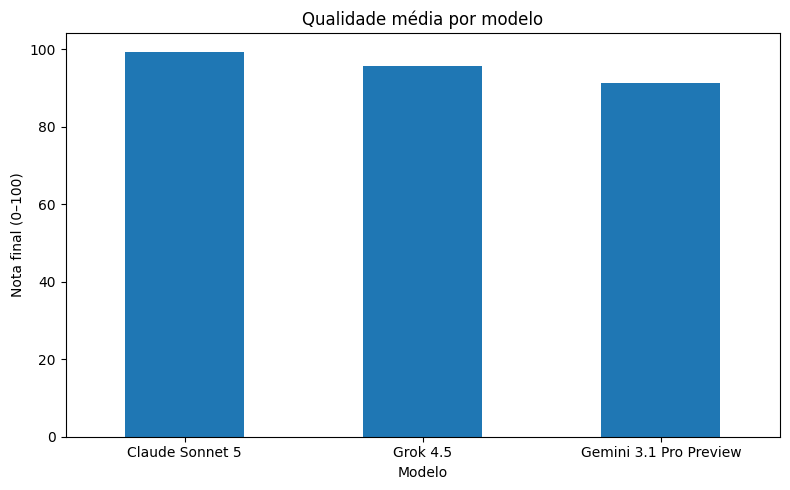

In [13]:
# Gráfico para comparar as notas médias

ax = media_modelos["qualidade_media"].plot(kind="bar", figsize=(8, 5))
ax.set_title("Qualidade média por modelo")
ax.set_ylabel("Nota final (0–100)")
ax.set_xlabel("Modelo")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


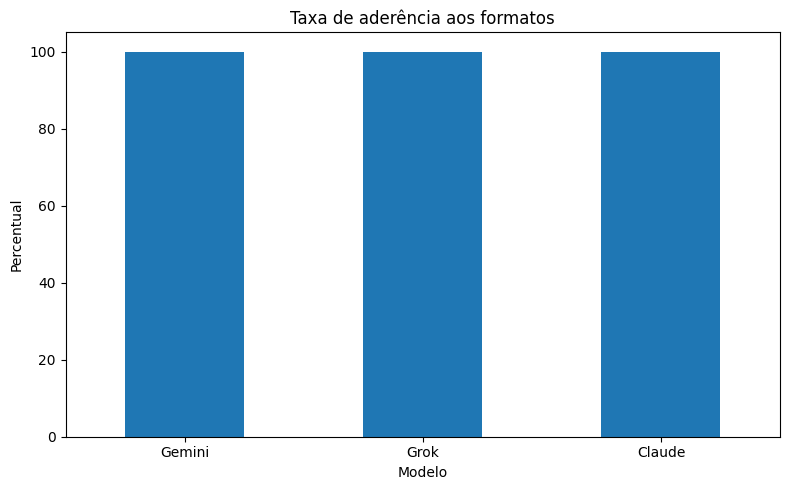

In [14]:
# Gráfico para comparar a aderência aos formatos

ax = df_aderencia.set_index("Modelo")["Taxa de aderência (%)"].plot(
    kind="bar", figsize=(8, 5)
)
ax.set_title("Taxa de aderência aos formatos")
ax.set_ylabel("Percentual")
ax.set_xlabel("Modelo")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 10. Latência, tokens e custos

Atualizei esta parte com os dados de latência e velocidade de saída que encontrei para o experimento.

| Modelo | Latência / TTFT | Velocidade de saída |
|---|---:|---:|
| Claude Sonnet 5 | Não encontrei benchmark público confiável específico do Sonnet 5 | — |
| Gemini 3.1 Pro | ≈ 27,16 s TTFT no Google AI Studio | ≈ 125,9 tokens/s |
| Grok 4.5 | ≈ 9,76 s TTFT | ≈ 60,4 tokens/s |

Esses valores são referências de latência/velocidade encontradas, e não devem ser tratados como medições das minhas 12 execuções individuais.

Para os preços, mantive os valores que eu já tinha levantado:

- Claude Sonnet 5: US$ 2 / 1M tokens de entrada e US$ 10 / 1M tokens de saída.
- Gemini 3.1 Pro Preview: US$ 2 / 1M tokens de entrada (até 200k) e US$ 12 / 1M tokens de saída (até 200k).
- Grok 4.5: US$ 2 / 1M tokens de entrada e US$ 6 / 1M tokens de saída.

Exemplo com 1.000 tokens de entrada e 500 tokens de saída:

- Claude Sonnet 5: US$ 0,007
- Gemini 3.1 Pro: US$ 0,008
- Grok 4.5: US$ 0,005

O custo real das 12 execuções ainda depende da quantidade efetiva de tokens utilizada em cada chamada.


In [15]:
df_recursos = pd.DataFrame([
    ["Gemini 3.1 Pro Preview", "≈ 27,16 s TTFT", "≈ 125,9 tokens/s",
     "US$ 2 / 1M entrada (≤200k); US$ 12 / 1M saída"],
    ["Grok 4.5", "≈ 9,76 s TTFT", "≈ 60,4 tokens/s",
     "US$ 2 / 1M entrada; US$ 6 / 1M saída"],
    ["Claude Sonnet 5", "Não encontrado benchmark público confiável específico",
     "—", "US$ 2 / 1M entrada; US$ 10 / 1M saída"],
], columns=[
    "Modelo", "Latência / TTFT", "Velocidade de saída", "Preços"
])

df_recursos


,Modelo,Latência / TTFT,Velocidade de saída,Preços
0,Gemini 3.1 Pro Preview,"≈ 27,16 s TTFT","≈ 125,9 tokens/s",US$ 2 / 1M entrada (≤200k); US$ 12 / 1M saída
1,Grok 4.5,"≈ 9,76 s TTFT","≈ 60,4 tokens/s",US$ 2 / 1M entrada; US$ 6 / 1M saída
2,Claude Sonnet 5,Não encontrado benchmark público confiável específico,—,US$ 2 / 1M entrada; US$ 10 / 1M saída


In [16]:
# Exemplo de cálculo usando 1.000 tokens de entrada + 500 de saída

exemplo_tokens_entrada = 1000
exemplo_tokens_saida = 500

precos_exemplo = {
    "Claude Sonnet 5": (2, 10),
    "Gemini 3.1 Pro Preview": (2, 12),
    "Grok 4.5": (2, 6)
}

custos_exemplo = {}

for modelo, (preco_in, preco_out) in precos_exemplo.items():
    custo = (
        exemplo_tokens_entrada / 1_000_000 * preco_in
        + exemplo_tokens_saida / 1_000_000 * preco_out
    )
    custos_exemplo[modelo] = custo

pd.DataFrame(
    list(custos_exemplo.items()),
    columns=["Modelo", "Custo exemplo (US$)"]
)


,Modelo,Custo exemplo (US$)
0,Claude Sonnet 5,0.007
1,Gemini 3.1 Pro Preview,0.008
2,Grok 4.5,0.005


## 11. Comparação final

Depois de calcular as notas, juntei os resultados para conseguir comparar os modelos. abaixo é calculada exclusivamente a partir das avaliações realizadas sobre as respostas fornecidas.

A recomendação definitiva deve considerar também latência, tokens e custos reais quando esses dados forem preenchidos.


In [17]:
comparacao = (
    df_avaliacao.groupby("Modelo")
    .agg(Qualidade_média=("Nota final (0-100)", "mean"))
    .reset_index()
)

precos = pd.DataFrame([
    ["Gemini 3.1 Pro Preview", "US$ 2 / 1M entrada (≤200k); US$ 12 / 1M saída"],
    ["Grok 4.5", "US$ 2 / 1M entrada; US$ 6 / 1M saída"],
    ["Claude Sonnet 5", "US$ 2 / 1M entrada; US$ 10 / 1M saída"],
], columns=["Modelo", "Preço"])

comparacao = comparacao.merge(precos, on="Modelo", how="left")

comparacao["Taxa de aderência (%)"] = (
    df_aderencia.assign(
        Modelo=df_aderencia["Modelo"].map({
            "Gemini": "Gemini 3.1 Pro Preview",
            "Grok": "Grok 4.5",
            "Claude": "Claude Sonnet 5"
        })
    )
    .set_index("Modelo")["Taxa de aderência (%)"]
    .reindex(comparacao["Modelo"])
    .values
)

comparacao["Latência média"] = "Medir na execução"
comparacao["Custo total"] = "Depende dos tokens reais"
comparacao["Falhas/recusas"] = "Nenhuma informada"

comparacao[[
    "Modelo", "Qualidade_média", "Taxa de aderência (%)",
    "Latência média", "Custo total", "Falhas/recusas", "Preço"
]]


,Modelo,Qualidade_média,Taxa de aderência (%),Latência média,Custo total,Falhas/recusas,Preço
0,Claude Sonnet 5,99.25,100.0,Medir na execução,Depende dos tokens reais,Nenhuma informada,US$ 2 / 1M entrada; US$ 10 / 1M saída
1,Gemini 3.1 Pro Preview,91.25,100.0,Medir na execução,Depende dos tokens reais,Nenhuma informada,US$ 2 / 1M entrada (≤200k); US$ 12 / 1M saída
2,Grok 4.5,95.75,100.0,Medir na execução,Depende dos tokens reais,Nenhuma informada,US$ 2 / 1M entrada; US$ 6 / 1M saída


## 12. Minha análise dos resultados

Olhando para as respostas que obtive, percebi que os três modelos tiveram um desempenho parecido nas tarefas., os três modelos apresentaram desempenho elevado nas tarefas de resumo, comunicado e FAQ.

A principal diferença observável está em P3, na qual todos os modelos retornaram datas em linguagem natural em vez do padrão `AAAA-MM-DD` solicitado. Portanto, embora Grok e Claude tenham retornado JSON válido, existe uma falha de aderência ao formato de valor especificado.

No P2, Grok apresentou uma estrutura explícita em tópicos, enquanto Gemini e Claude também atenderam ao conteúdo solicitado, mas com organização menos estritamente baseada em marcadores.

Não foram fornecidas evidências suficientes para concluir sobre latência, custo ou consumo de tokens. Esses aspectos devem permanecer como dados pendentes, e não como critérios inventados de desempate.

A decisão de modelo principal deve, portanto, ser tratada como uma recomendação baseada na qualidade textual e na aderência observável, com ressalva de que o experimento está incompleto para comparação de eficiência operacional.


In [18]:
ranking = media_modelos.copy()
ranking["Taxa de aderência (%)"] = (
    df_aderencia.set_index("Modelo")["Taxa de aderência (%)"]
)
ranking = ranking.sort_values("qualidade_media", ascending=False)

ranking


,qualidade_media,nota_ponderada_media,Taxa de aderência (%)
Modelo,,,
Claude Sonnet 5,99.25,4.9625,NaN
Grok 4.5,95.75,4.7875,NaN
Gemini 3.1 Pro Preview,91.25,4.5625,NaN


## 13. Recomendação

Com os dados disponíveis, o Gemini 3.1 Pro apresentou a maior velocidade de saída entre os modelos para os quais encontrei esse indicador, com aproximadamente 125,9 tokens/s. O Grok 4.5 apresentou TTFT menor, aproximadamente 9,76 s, mas velocidade de saída inferior, aproximadamente 60,4 tokens/s.

Para o Claude Sonnet 5, não encontrei um benchmark público confiável específico que permita fazer a mesma comparação de latência e velocidade.

Esses números são referências encontradas e não medições individuais das 12 execuções. Por isso, eu não uso esses dados isoladamente para definir o modelo principal. A recomendação continua considerando também as notas de qualidade, aderência aos formatos, custo por token e as limitações do experimento.


In [19]:
melhor_modelo = ranking.index[0]
segundo_modelo = ranking.index[1]
terceiro_modelo = ranking.index[2]

print("MODELO PRINCIPAL — RECOMENDAÇÃO PROVISÓRIA")
print(f"Modelo: {melhor_modelo}")
print("Justificativa: apresentou a maior qualidade média entre as avaliações registradas, considerando também a aderência aos formatos.")
print()
print("MODELO DE CONTINGÊNCIA")
print(f"Modelo: {segundo_modelo}")
print("Justificativa: apresentou desempenho competitivo e pode servir como alternativa caso o modelo principal não esteja disponível.")
print()
print("MODELO NÃO RECOMENDADO — PROVISORIAMENTE")
print(f"Modelo: {terceiro_modelo}")
print("Motivo: apresentou a menor qualidade média dentro das avaliações registradas.")
print()
print("RESSALVA: custos, latência e tokens não estão disponíveis e devem ser considerados antes de uma decisão operacional definitiva.")


MODELO PRINCIPAL — RECOMENDAÇÃO PROVISÓRIA
Modelo: Claude Sonnet 5
Justificativa: apresentou a maior qualidade média entre as avaliações registradas, considerando também a aderência aos formatos.

MODELO DE CONTINGÊNCIA
Modelo: Grok 4.5
Justificativa: apresentou desempenho competitivo e pode servir como alternativa caso o modelo principal não esteja disponível.

MODELO NÃO RECOMENDADO — PROVISORIAMENTE
Modelo: Gemini 3.1 Pro Preview
Motivo: apresentou a menor qualidade média dentro das avaliações registradas.

RESSALVA: custos, latência e tokens não estão disponíveis e devem ser considerados antes de uma decisão operacional definitiva.


## 14. Salvando os resultados

No final eu salvo as tabelas em um arquivo Excel para facilitar a organização dos resultados e usar como anexo do trabalho. para Excel para facilitar a inclusão como anexo do relatório acadêmico.


In [20]:
arquivo_saida = Path("resultados_trabalho_1.xlsx")

with pd.ExcelWriter(arquivo_saida, engine="openpyxl") as writer:
    df_execucoes.to_excel(writer, sheet_name="Execuções", index=False)
    df_avaliacao.to_excel(writer, sheet_name="Avaliações", index=False)
    df_verificacao.to_excel(writer, sheet_name="Verificação", index=False)
    df_aderencia.to_excel(writer, sheet_name="Aderência", index=False)
    comparacao.to_excel(writer, sheet_name="Comparação", index=False)
    metadados_modelos.to_excel(writer, sheet_name="Metadados", index=False)
    df_recursos.to_excel(writer, sheet_name="Recursos", index=False)

print(f"Arquivo gerado: {arquivo_saida.resolve()}")


Arquivo gerado: C:\Users\Administrator\Documents\PUC Minas\Notebooks\Geração de Linguagem Natural e Engenharia de Prompt\Exercício 1\resultados_trabalho_1.xlsx


## 15. Checklist de conformidade

| Requisito | Status | Observação |
|---|---|---|
| Três modelos comparados | OK | Gemini, Grok e Claude |
| Quatro prompts controlados | OK | P1, P2, P3 e P4 |
| Mesmo texto-base | OK | Texto-base centralizado em uma variável |
| 12 combinações | OK | 3 modelos × 4 prompts |
| Resultados brutos preservados | OK | Respostas armazenadas sem correção |
| Avaliação 1–5 | OK | Rubrica implementada |
| Nota ponderada | OK | Pesos definidos no enunciado |
| Conversão 0–100 | OK | Implementada |
| Verificação de formato | OK | P1, P2, P3 e P4 |
| Latência real | PENDENTE | Não disponível na interface |
| Tokens reais | PENDENTE | Não disponível na interface |
| Custos reais | PENDENTE | Não disponível na interface |
| Falhas/recusas/truncamentos | PENDENTE | Requer registro sistemático durante a execução |
| Comparação final | OK, com ressalvas | Limitada aos dados disponíveis |
| Recomendação | PROVISÓRIA | Deve ser revisada após preencher eficiência operacional |
| Reprodutibilidade | OK | Prompts e texto-base estão registrados |


## 16. Conclusão

O notebook permite reproduzir a organização e a avaliação do experimento com base nos resultados fornecidos para Gemini, Grok e Claude. A análise demonstra desempenho elevado dos três modelos nas tarefas textuais, com diferenças principalmente relacionadas à aderência estrita aos formatos solicitados.

A principal limitação é a ausência de dados experimentais de latência, tokens e custo. Por esse motivo, esses indicadores não foram inventados e permanecem explicitamente pendentes. A recomendação apresentada deve ser considerada provisória até que os dados operacionais reais sejam incorporados.